# 03 · Price forecast

What will a crop sell for at harvest? The farmer sows now and sells 3–12 months later, so we forecast
**12 months ahead** from the last month of data (May 2026).

- **Series:** monthly median mandi price (Rs/quintal) per crop × state, plus an all-India series per crop.
- **Methods:** last value (naive), seasonal-naive (same month last year), their average (blend),
  and Prophet (default settings, yearly seasonality, on log price).
- **Backtest:** rolling origin. Cutoffs May 2024, Nov 2024, May 2025; each forecasts the next 12 months.
  A series needs ≥ 24 months before the cutoff. Scored by MAPE, only on months where every method has a forecast.
- **Choice:** the method with the lowest median MAPE at **4–12 months ahead**, the gap between sowing and selling.
  Short-horizon accuracy doesn't matter here: nobody harvests a month after sowing.

Outputs: `research/results/2026-11-03_price_backtest.csv`, figures in `research/figures/`.
The app's forecast file is written by notebook 06, section 4 (Nov 3 update).

In [1]:
import sys
sys.path.insert(0, '../project')
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet

import data

logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').disabled = True
RESULTS, FIGS, PROCESSED = Path('../research/results'), Path('../research/figures'), Path('../data/processed')
CUTOFFS = pd.to_datetime(['2024-05-01', '2024-11-01', '2025-05-01'])
H, MIN_TRAIN = 12, 24
COLORS = ['#bdbdbd', '#a5d6a7', '#66bb6a', '#1b5e20']
pd.set_option('display.width', 200)

Importing plotly failed. Interactive plots will not work.


## 1. Data

All-India series = market-day-weighted mean of the state medians. The mix of states changes with the season
(especially for fruit), so this series is noisier than a single state's.

In [2]:
prices = data.mandi_prices()
national = (prices.assign(w=prices.price * prices.n).groupby(['crop', 'month'])[['w', 'n']].sum()
            .eval('price = w / n').reset_index()[['crop', 'month', 'price', 'n']].assign(state='All India'))
series = pd.concat([prices, national])[['crop', 'state', 'month', 'price', 'n']]
print(series.month.min().date(), '→', series.month.max().date(), '|', series.groupby(['crop', 'state']).ngroups, 'series')

2021-01-01 → 2026-05-01 | 417 series


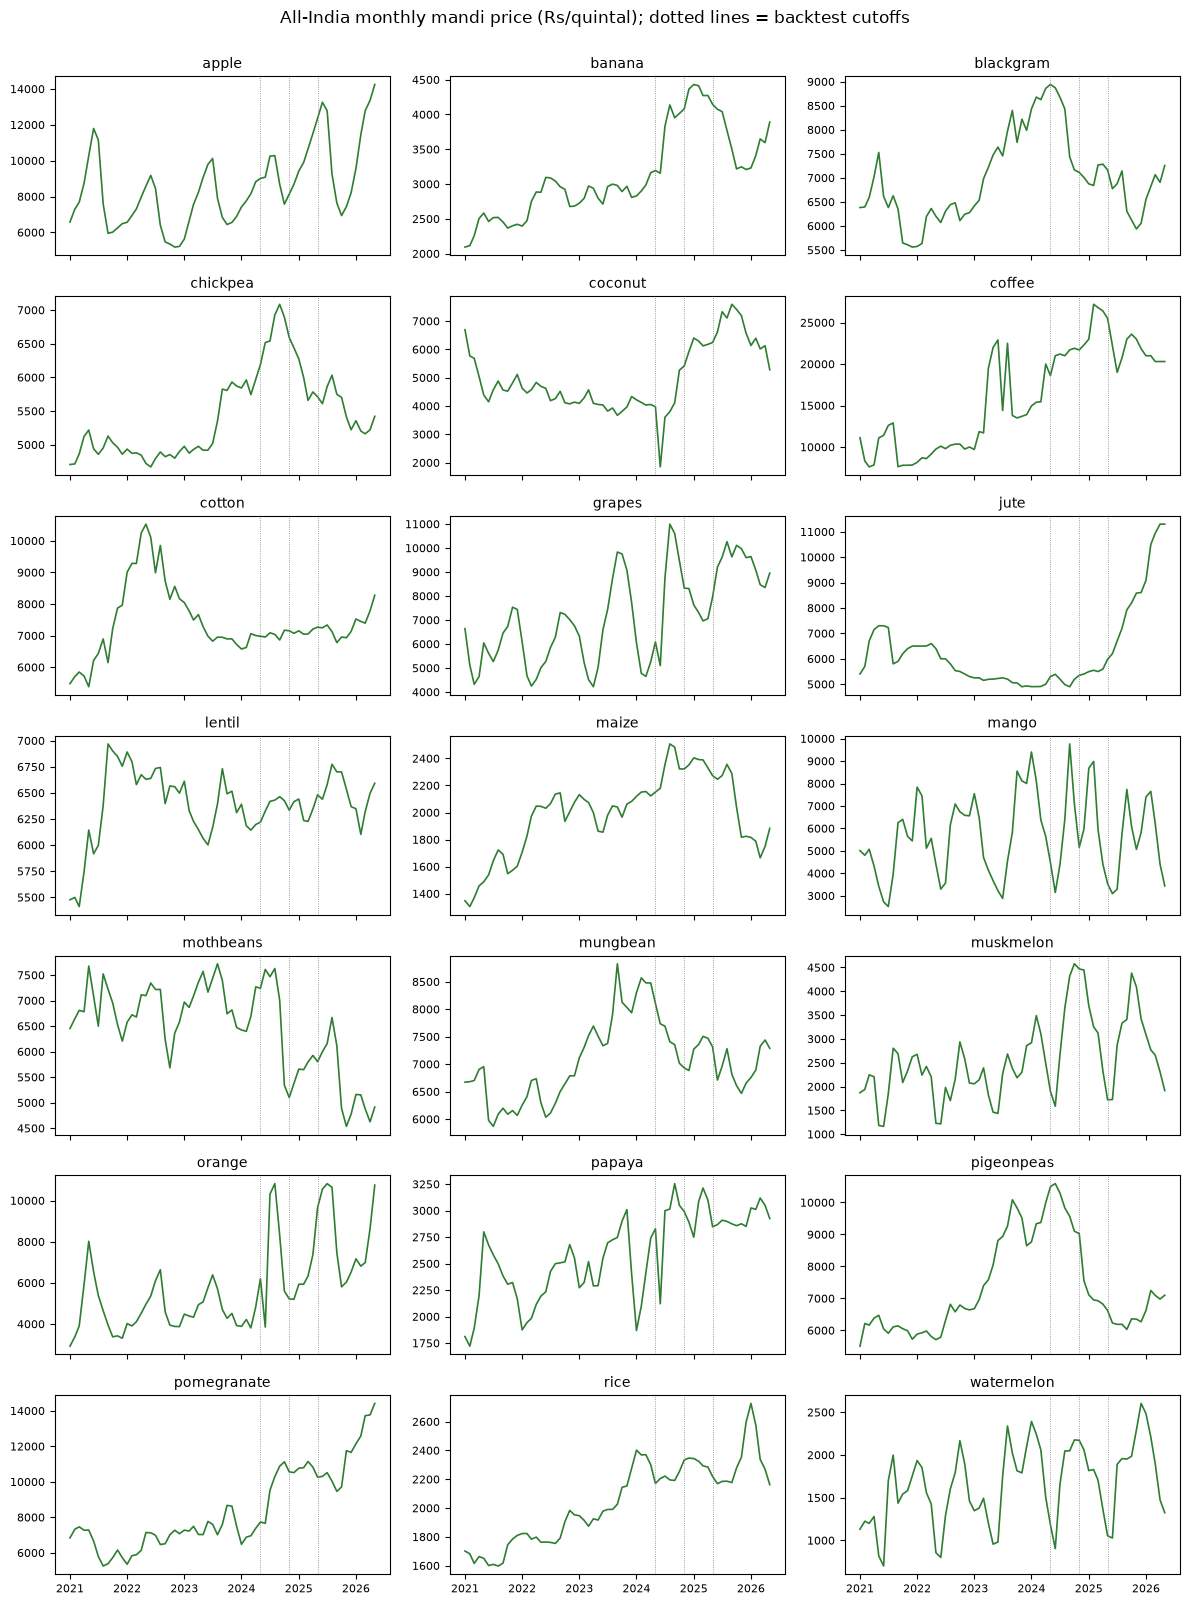

In [3]:
crops = sorted(national.crop.unique())
fig, axes = plt.subplots(7, 3, figsize=(12, 16), sharex=True)
for ax, crop in zip(axes.flat, crops):
    s = national[national.crop == crop]
    ax.plot(s.month, s.price, color='#2e7d32', lw=1.2)
    for c in CUTOFFS:
        ax.axvline(c, color='grey', lw=0.6, ls=':')
    ax.set_title(crop, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle('All-India monthly mandi price (Rs/quintal); dotted lines = backtest cutoffs', y=1.0)
fig.tight_layout()
fig.savefig(FIGS / 'price_series.png', dpi=130)

## 2. Backtest

In [4]:
def forecasts(train: pd.Series, months: pd.DatetimeIndex, prophet: bool = True) -> pd.DataFrame:
    """Forecast `months` from `train` (price indexed by month) with every method."""
    f = pd.DataFrame({'naive': train.iloc[-1], 'seasonal_naive': train.reindex(months - pd.DateOffset(years=1)).values}, index=months)
    f['blend'] = (f.naive + f.seasonal_naive) / 2
    if prophet:
        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m.fit(pd.DataFrame({'ds': train.index, 'y': np.log(train.values)}))
        f['prophet'] = np.exp(m.predict(pd.DataFrame({'ds': months})).yhat.values)
    return f


rows = []
for (crop, state), g in series.groupby(['crop', 'state']):
    s = g.set_index('month').price.sort_index()
    for cut in CUTOFFS:
        train, test = s[s.index <= cut], s[(s.index > cut) & (s.index <= cut + pd.DateOffset(months=H))]
        if len(train) < MIN_TRAIN or test.empty:
            continue
        f = forecasts(train, test.index).assign(crop=crop, state=state, cutoff=cut, actual=test.values)
        f['h'] = (f.index.year - cut.year) * 12 + f.index.month - cut.month
        rows.append(f.dropna())
bt = pd.concat(rows).rename_axis('month').reset_index()
METHODS = ['naive', 'seasonal_naive', 'blend', 'prophet']
for m in METHODS:
    bt[f'ape_{m}'] = (bt[m] - bt.actual).abs() / bt.actual * 100
print(len(bt), 'forecast-months from', bt.groupby(['crop', 'state']).ngroups, 'series')

8431 forecast-months from 296 series


MAPE per series first, then averaged, so a series with 36 test months doesn't count three times more than
one with 12. Median as well as mean, because a few volatile fruit series in small states have huge errors.

In [5]:
APE = [f'ape_{m}' for m in METHODS]
per_series = bt.groupby(['crop', 'state'])[APE].mean().set_axis(METHODS, axis=1)
harvest = bt[bt.h >= 4].groupby(['crop', 'state'])[APE].mean().set_axis(METHODS, axis=1)
is_nat = per_series.index.get_level_values('state') == 'All India'
summary = pd.DataFrame({
    '4–12 months, median MAPE': harvest.median(),
    'all series, mean MAPE': per_series.mean(),
    'all series, median MAPE': per_series.median(),
    'state series, median MAPE': per_series[~is_nat].median(),
    'All-India series, median MAPE': per_series[is_nat].median(),
    'share of series where best': per_series.idxmin(axis=1).value_counts(normalize=True).reindex(METHODS).fillna(0) * 100,
}).round(1)
summary

,"4–12 months, median MAPE","all series, mean MAPE","all series, median MAPE","state series, median MAPE","All-India series, median MAPE",share of series where best
naive,19.4,29.6,16.8,17.5,16.4,42.6
seasonal_naive,17.3,30.5,17.3,17.5,17.1,23.6
blend,17.5,27.9,16.7,16.7,17.3,26.4
prophet,22.9,777305882.7,22.8,22.9,18.2,7.4


/tmp/ipykernel_375748/3118786583.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_h = bt.groupby([bands, 'crop', 'state'], observed=True)[APE].mean().groupby(level=0).median().set_axis(METHODS, axis=1)


,naive,seasonal_naive,blend,prophet
h,,,,
1–3 months,9.9,15.9,11.4,16.4
4–6 months,16.7,16.0,15.2,18.5
7–12 months,18.4,17.5,17.1,23.7


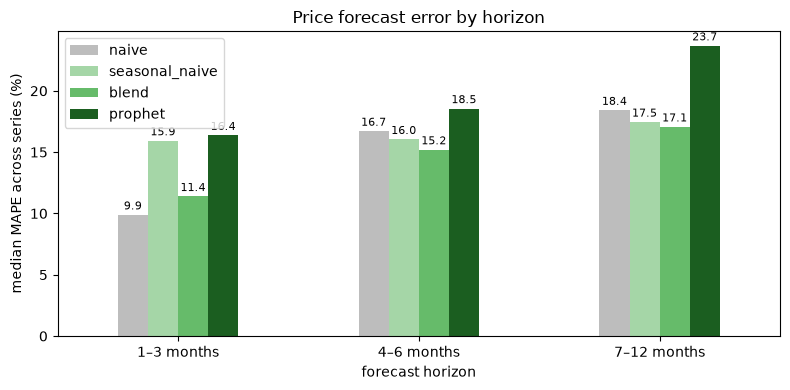

In [6]:
bands = pd.cut(bt.h, [0, 3, 6, 12], labels=['1–3 months', '4–6 months', '7–12 months'])
by_h = bt.groupby([bands, 'crop', 'state'], observed=True)[APE].mean().groupby(level=0).median().set_axis(METHODS, axis=1)
ax = by_h.plot.bar(figsize=(8, 4), rot=0, color=COLORS)
ax.set_ylabel('median MAPE across series (%)')
ax.set_xlabel('forecast horizon')
ax.set_title('Price forecast error by horizon')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(FIGS / 'price_mape_by_horizon.png', dpi=150)
by_h.round(1)

Per crop, on the All-India series (the fallback for any state without its own forecast) and the median over state series.

In [7]:
per_crop = pd.concat({
    'All India': per_series[is_nat].droplevel('state'),
    'states (median)': per_series[~is_nat].groupby('crop').median(),
}, axis=1).round(1)
per_crop[('states (median)', 'n_series')] = per_series[~is_nat].groupby('crop').size()
per_crop = per_crop.sort_values(('All India', 'prophet'))

out = per_series.round(2).reset_index()
out['best'] = per_series.idxmin(axis=1).values
out.to_csv(RESULTS / '2026-11-03_price_backtest.csv', index=False)
per_crop

All India                              states (median)                                      
                naive seasonal_naive blend prophet           naive seasonal_naive blend prophet n_series
crop                                                                                                    
rice              4.6            3.6   3.7     3.8             6.0            7.2   6.7     8.2       19
cotton            2.6            3.7   3.0     5.1             6.4            7.8   5.9     9.4       11
lentil            2.6            2.5   2.2     6.5             2.8            5.9   4.2     5.2        6
mothbeans        16.4           16.3  12.1    10.3            12.3           15.3  11.6    14.1        4
blackgram        11.4           17.2  13.9    11.8            12.6           20.6  14.9    21.4       14
mungbean          7.1            9.8   7.3    12.7            10.9           14.1  11.9    13.7       11
chickpea          8.5           13.1  10.3    13.3             8.7           13.3  10.4    19.9       15
papaya            5.4           12.0   7.8    15.1            14.4           16.6  11.9    26.2       19
maize            10.4           14.6  12.2    16.0            10.3           13.9  11.5    16.9       16
watermelon       36.3           12.9  20.3    17.5            38.9           20.7  28.9    22.8       16
grapes           18.0           18.3  15.1    18.2            24.5           23.5  22.8    37.0       16
jute             16.7           21.6  19.1    18.6            16.6           21.7  19.1    18.5        1
mango            30.8           17.7  17.3    20.2            36.1           22.9  29.3    43.3       17
apple            20.7           17.1  17.4    20.6            28.4           15.3  18.3    22.9       19
orange           27.1           24.8  21.6    24.7            31.6           21.7  21.6    27.4       19
pomegranate      14.1           21.7  17.7    29.4            16.6           15.3  12.6    21.7       17
coffee           16.4           21.7  18.0    33.1            16.4           21.7  18.0    33.1        1
pigeonpeas       24.1           33.3  28.5    33.8            20.8           30.2  25.1    29.7       13
muskmelon        44.1           16.2  24.7    34.4            34.9           21.8  25.4    33.0       11
banana           15.9           23.9  19.7    39.0            11.9           19.2  17.0    27.0       23
coconut          20.4           32.4  26.4    41.3            33.7           37.7  36.2    36.4        7

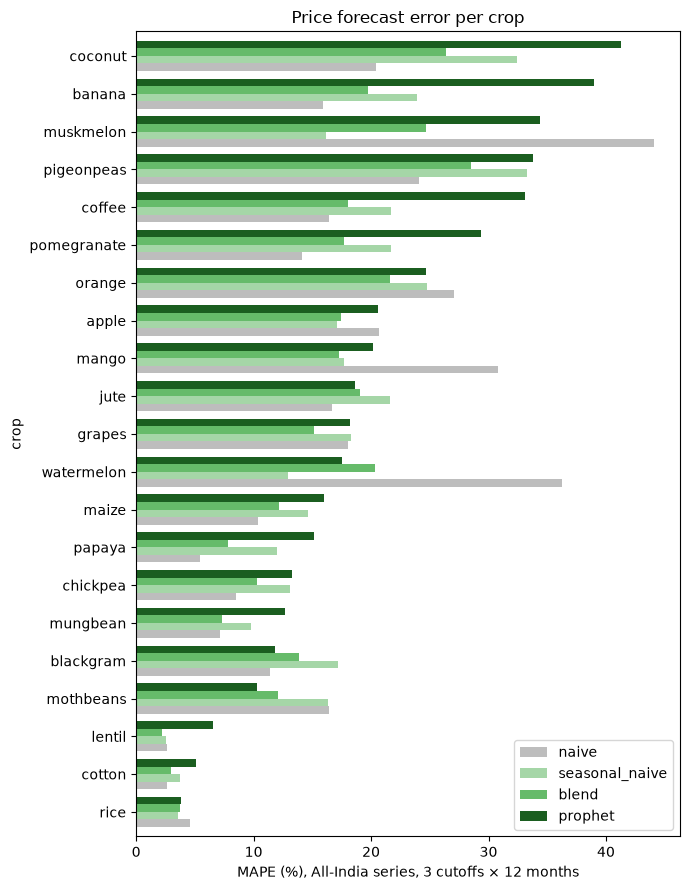

In [8]:
p = per_crop['All India'][METHODS]
ax = p.plot.barh(figsize=(7, 9), color=COLORS, width=0.8)
ax.set_xlabel('MAPE (%), All-India series, 3 cutoffs × 12 months')
ax.set_title('Price forecast error per crop')
plt.tight_layout()
plt.savefig(FIGS / 'price_mape_by_crop.png', dpi=150)

## 3. Pick the method

In [9]:
best = summary['4–12 months, median MAPE'].idxmin()
print('Lowest median MAPE at 4–12 months:', best)
print(summary['4–12 months, median MAPE'].to_string())

Lowest median MAPE at 4–12 months: seasonal_naive
naive             19.4
seasonal_naive    17.3
blend             17.5
prophet           22.9


What a forecast looks like: the last backtest origin (May 2025) for four big crops, All-India series.

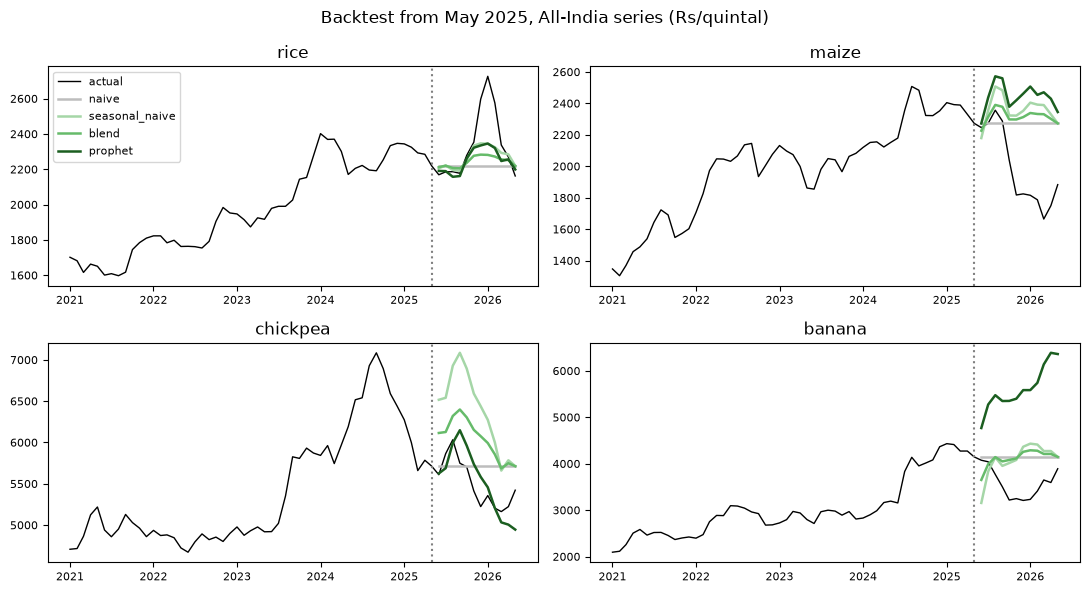

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
last = CUTOFFS[-1]
for ax, crop in zip(axes.flat, ['rice', 'maize', 'chickpea', 'banana']):
    s = national[national.crop == crop].set_index('month').price
    f = bt[(bt.crop == crop) & (bt.state == 'All India') & (bt.cutoff == last)].set_index('month')
    ax.plot(s.index, s, color='black', lw=1, label='actual')
    for m, col in zip(METHODS, COLORS):
        ax.plot(f.index, f[m], color=col, lw=1.8, label=m)
    ax.axvline(last, color='grey', ls=':')
    ax.set_title(crop)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=8)
fig.suptitle('Backtest from May 2025, All-India series (Rs/quintal)')
fig.tight_layout()
fig.savefig(FIGS / 'price_backtest_examples.png', dpi=150)

## 4. Forecast June 2026 – May 2027

Every series with ≥ 24 months gets a 12-month forecast with the chosen method. `mape` is that series' backtest error,
at 4–12 months ahead, so the app and agent can say how much to trust the number. Seasonal-naive has no forecast for a month that's missing a
year earlier; the ranker then falls back to the All-India series.

In [11]:
future = pd.date_range(series.month.max() + pd.DateOffset(months=1), periods=H, freq='MS')
fc = []
for (crop, state), g in series.groupby(['crop', 'state']):
    s = g.set_index('month').price.sort_index()
    if len(s) < MIN_TRAIN:
        continue
    f = forecasts(s, future, prophet=best == 'prophet')[best]
    fc.append(pd.DataFrame({'crop': crop, 'state': state, 'month': future, 'price': f.values}))
fc = pd.concat(fc).dropna()
fc['method'] = best
fc = fc.merge(harvest[best].rename('mape').round(1).reset_index(), on=['crop', 'state'], how='left')
fc['price'] = fc.price.round(0)
print(len(fc), 'rows,', fc.groupby(['crop', 'state']).ngroups, 'series,', fc.crop.nunique(), 'crops')
fc[fc.state == 'All India'].pivot(index='crop', columns='month', values='price').iloc[:, ::3]

3368 rows, 309 series, 21 crops


month,2026-06-01,2026-09-01,2026-12-01,2027-03-01
crop,,,,
apple,13258.0,7635.0,8207.0,12782.0
banana,4074.0,3502.0,3209.0,3649.0
blackgram,6774.0,6304.0,6055.0,7065.0
chickpea,5609.0,5749.0,5223.0,5163.0
coconut,6610.0,7593.0,6569.0,6016.0
coffee,22200.0,23000.0,21850.0,20300.0
cotton,7248.0,6778.0,7133.0,7395.0
grapes,9202.0,9628.0,9597.0,8469.0
jute,6202.0,7925.0,8608.0,10942.0


## Findings (Nov 3)

- **Prophet loses.** At 4–12 months ahead its median MAPE is 22.9%, against 17.3% for seasonal-naive.
  On short state series it extrapolates the trend wildly: 21 of 296 series go above 100% error (worst: muskmelon in
  Jammu and Kashmir), which is why its mean MAPE is absurd. Default settings, no tuning.
- **Last value wins at 1–3 months (9.9%) but loses at harvest horizons (19.4%)**, and it can't show seasons:
  it says mango sells the same in June and September, while seasonal-naive says September pays 2.5× more.
- Seasonal-naive (17.3%) and the blend (17.5%) tie at 4–12 months. **We use seasonal-naive**: it's the simpler one,
  and the plan named it as the baseline.
- Field crops are predictable (rice, cotton, lentil: 2–7% on the All-India series). Fruit and pigeonpeas are not (17–44%).
  The `mape` column carries this to the app, so a banana forecast can be shown as rougher than a rice one.
- 309 series forecast: 21 crops all-India, plus 288 crop × state series. kidneybeans has no price data at all.
- Limits: 5 years of data, 3 backtest origins.
- **Nov 3 update:** notebook 06 found a median combination of ETS, ARIMA, Theta and seasonal-naive beats
  seasonal-naive (16.5% vs 17.4%). The app now uses that; this notebook's forecast above is no longer saved.